# pixel-wm : planification CEM dans le modèle du monde

Ce notebook **utilise les checkpoints déjà entraînés** (dossier `runs/` de ton Drive) : aucun réentraînement.
Pour chaque checkpoint, un planificateur CEM choisit les actions **en imaginant le futur avec le modèle** (il ne voit que des pixels), et on mesure le **retour réel** obtenu dans l'environnement `point_reach`, comparé à deux références évaluées sur *exactement les mêmes épisodes* :
- **aléatoire** (borne basse) ;
- **oracle** : un contrôleur qui lit l'état du simulateur (borne haute, inaccessible à un agent pixel).

Le « score » est normalisé : 0 = aussi mauvais que l'aléatoire, 1 = aussi bon que l'oracle.

On évalue aussi la **tête de reward** (jamais vérifiée jusqu'ici) et on regarde si la qualité de prédiction est liée au retour obtenu.
Mets `QUICK = True` pour tout tester en quelques minutes.

## 0. Configuration

In [1]:
QUICK = False        # True: 3 episodes on the first checkpoint only
BASE = "/content/drive/MyDrive/pixel-wm"
REPO = "/content/pixel-wm"
RUNS = f"{BASE}/runs"          # folder holding the trained runs (<run>/checkpoints/last.pt)
EPISODES = 3 if QUICK else 100  # real-environment episodes per checkpoint (30 was too noisy)
SEED = 1000                    # first episode seed (identical for CEM / random / oracle)
CEM = dict(horizon=6, samples=1024, elites=128, iterations=4)  # best of the grid in section 8

## 1. Drive, code, installation

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")
!nvidia-smi -L

Mounted at /content/drive
GPU 0: Tesla T4 (UUID: GPU-76e44a28-4bdd-a8f4-6a0a-f42b738daba0)


In [3]:
%cd /content
!rm -rf pixel-wm
!git clone https://github.com/bamont/pixel-world-models.git pixel-wm
%cd /content/pixel-wm
!pip install -q -e ".[dev]"

import importlib, sys
importlib.invalidate_caches()
sys.path.insert(0, f"{REPO}/src")
import torch
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
!git log --oneline | head -3

/content
Cloning into 'pixel-wm'...
remote: Enumerating objects: 139, done.
remote: Counting objects: 100% (139/139), done.
remote: Compressing objects: 100% (93/93), done.
remote: Total 139 (delta 40), reused 129 (delta 30), pack-reused 0 (from 0)
Receiving objects: 100% (139/139), 50.51 KiB | 3.88 MiB/s, done.
Resolving deltas: 100% (40/40), done.
/content/pixel-wm
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.5/15.5 MB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 59.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.0/258.0 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━

### Vérifier que le dépôt contient le planificateur, puis lancer les tests

In [4]:
import pathlib, re
checks = {
    "src/pixelwm/planning/cem.py": "class CEMPlanner",
    "src/pixelwm/planning/policies.py": "class OraclePolicy",
    "src/pixelwm/planning/rollout.py": "def evaluate_policy",
    "scripts/plan.py": "CEMPlanner",
    "src/pixelwm/eval/rollout.py": "reward_mae",
}
ok = True
for path, pattern in checks.items():
    p = pathlib.Path(REPO, path)
    found = p.exists() and re.search(pattern, p.read_text()) is not None
    ok &= found
    print(("OK      " if found else "MISSING ") + path)
assert ok, "Planning files missing from the GitHub repo: commit and push them, then re-run the clone cell."

OK      src/pixelwm/planning/cem.py
OK      src/pixelwm/planning/policies.py
OK      src/pixelwm/planning/rollout.py
OK      scripts/plan.py
OK      src/pixelwm/eval/rollout.py


In [5]:
!pytest -q

............................................                             [100%]


## 2. Fonctions utilitaires

In [6]:
import json, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

def run_dir(name):
    return pathlib.Path(RUNS) / name

def find_runs():
    return sorted(p.name for p in pathlib.Path(RUNS).iterdir() if (p / "checkpoints" / "last.pt").exists())

def plan(name, out="planning", episodes=None, gif=False, baselines=True, force=False, **cem):
    """Run scripts/plan.py on one checkpoint (skipped if its result file already exists)."""
    out_dir = run_dir(name) / out
    if (out_dir / "planning.json").exists() and not force:
        return out_dir
    p = {**CEM, **cem}
    cmd = ["python", "scripts/plan.py", "--checkpoint", str(run_dir(name) / "checkpoints" / "last.pt"),
           "--episodes", str(episodes or EPISODES), "--seed", str(SEED),
           "--horizon", str(p["horizon"]), "--samples", str(p["samples"]),
           "--elites", str(p["elites"]), "--iterations", str(p["iterations"]), "--out", str(out_dir)]
    if gif: cmd.append("--gif")
    if not baselines: cmd.append("--no-baselines")
    t0 = time.time()
    r = subprocess.run(cmd, cwd=REPO, capture_output=True, text=True)
    if r.returncode != 0:
        print(name, "FAILED\n", r.stderr[-1500:])
        return None
    lines = r.stdout.strip().splitlines()[:-1]
    print(f"{name} [{out}] done in {time.time() - t0:.0f}s\n" + "\n".join("   " + l for l in lines))
    return out_dir

def load_plan(name, out="planning"):
    path = run_dir(name) / out / "planning.json"
    return json.load(open(path))["results"] if path.exists() else None

def evaluate_v2(name, force=False):
    """Prediction metrics incl. the new reward-head metrics, on 100 fresh episodes."""
    out = run_dir(name) / "eval_v2"
    if (out / "metrics.json").exists() and not force:
        return
    cmd = ["python", "scripts/evaluate.py", "--checkpoint", str(run_dir(name) / "checkpoints" / "last.pt"),
           "--episodes", "100", "--sequences", "256", "--objects", "--out", str(out)]
    r = subprocess.run(cmd, cwd=REPO, capture_output=True, text=True)
    if r.returncode != 0:
        print(name, "evaluation FAILED\n", r.stderr[-1500:])

def load_eval(name):
    path = run_dir(name) / "eval_v2" / "metrics.json"
    return json.load(open(path)) if path.exists() else None

RUNS_FOUND = find_runs()
if QUICK:
    RUNS_FOUND = RUNS_FOUND[:1]
print("checkpoints found:", RUNS_FOUND)
assert RUNS_FOUND, f"No checkpoint found under {RUNS}"

checkpoints found: ['fg0_1000ep_s1', 'fg20_1000ep_s1', 'fg20_1000ep_s2', 'fg20_1000ep_s3', 'fg5_1000ep_s1', 'fg5_1000ep_s2', 'fg5_1000ep_s3']


## 3. Test rapide : un checkpoint, 3 épisodes, avec GIF
Vérifie que tout fonctionne et donne le **temps par pas** (indicatif pour dimensionner la suite). Le GIF montre le point rouge piloté par le planificateur.

fg0_1000ep_s1 [planning_smoke] done in 23s
   cem: return   -42.20 ± 26.65 | final dist 0.839 | success 0.00 | 58.5 ms/step
    random: return   -41.73 ± 22.37 | final dist 0.932 | success 0.00 | 0.2 ms/step
    oracle: return    -3.26 ±  3.16 | final dist 0.000 | success 1.00 | 0.1 ms/step


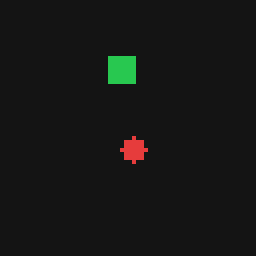

In [7]:
d = plan(RUNS_FOUND[0], out="planning_smoke", episodes=3, gif=True, force=True)
if d is not None:
    display(Image(filename=str(d / "plan.gif")))

## 4. Planification sur tous les checkpoints
Chaque checkpoint est traité une fois (les résultats existants sont réutilisés). Prévois environ 4 à 6 minutes par checkpoint avec 100 épisodes (estimation d'après 38 ms par pas) ; relance la cellule en cas de coupure, elle reprend où elle s'est arrêtée.

In [8]:
for name in RUNS_FOUND:
    plan(name)

## 5. Résultats : retour réel
`score` = (retour CEM − aléatoire) / (oracle − aléatoire) : 0 = aléatoire, 1 = oracle. `success` = fraction d'épisodes finis à moins de 0,1 du but.

In [9]:
def planning_table(out="planning"):
    rows = []
    for n in RUNS_FOUND:
        res = load_plan(n, out)
        if res is None:
            continue
        c, r, o = res["cem"], res.get("random"), res.get("oracle")
        row = {"run": n, "variant": n.split("_")[0], "cem_return": c["return_mean"], "cem_sd": c["return_std"],
               "final_dist": c["final_distance_mean"], "success": c["success_rate"],
               "ms_per_step": 1000 * c["seconds_per_step"]}
        if r and o:
            row["random"], row["oracle"] = r["return_mean"], o["return_mean"]
            row["score"] = (c["return_mean"] - r["return_mean"]) / (o["return_mean"] - r["return_mean"])
        rows.append(row)
    return pd.DataFrame(rows)

table = planning_table()
display(table.round(3))
if len(table) and "score" in table:
    print("Mean over seeds, by variant:")
    display(table.groupby("variant")[["cem_return", "final_dist", "success", "score"]].agg(["mean", "std"]).round(3))

,run,variant,cem_return,cem_sd,final_dist,success,ms_per_step,random,oracle,score
0,fg0_1000ep_s1,fg0,-37.177,16.806,0.726,0.033,64.729,-39.43,-2.502,0.061
1,fg20_1000ep_s1,fg20,-4.809,2.746,0.039,0.933,65.088,-39.43,-2.502,0.938
2,fg20_1000ep_s2,fg20,-5.665,2.904,0.060,0.800,64.893,-39.43,-2.502,0.914
3,fg20_1000ep_s3,fg20,-4.840,2.365,0.043,1.000,64.435,-39.43,-2.502,0.937
4,fg5_1000ep_s1,fg5,-5.152,2.476,0.047,0.967,65.218,-39.43,-2.502,0.928
5,fg5_1000ep_s2,fg5,-8.425,3.855,0.125,0.467,64.449,-39.43,-2.502,0.840
6,fg5_1000ep_s3,fg5,-5.423,2.890,0.051,0.900,64.144,-39.43,-2.502,0.921


Mean over seeds, by variant:


cem_return        final_dist        success         score       
              mean    std       mean    std    mean    std   mean    std
variant                                                                 
fg0        -37.177    NaN      0.726    NaN   0.033    NaN  0.061    NaN
fg20        -5.104  0.485      0.047  0.011   0.911  0.102  0.930  0.013
fg5         -6.333  1.816      0.074  0.044   0.778  0.271  0.896  0.049

## 6. La tête de reward et la qualité de prédiction
Le planificateur ne s'appuie que sur la tête de reward : `reward_mae@h` (erreur absolue moyenne) doit être **nettement sous** `reward_mae_copy@h` (répéter la dernière récompense observée). Le reward vaut −distance, donc il varie entre 0 et −2,8 environ.

In [10]:
for name in RUNS_FOUND:
    evaluate_v2(name)

keys = [f"{m}@{h}" for m in ("reward_mae", "reward_mae_copy", "psnr", "agent_err") for h in (1, 5, 15, 45)]
ev = pd.DataFrame({n: load_eval(n) for n in RUNS_FOUND if load_eval(n)}).astype(float)
display(ev.reindex(keys).round(3))

,fg0_1000ep_s1,fg20_1000ep_s1,fg20_1000ep_s2,fg20_1000ep_s3,fg5_1000ep_s1,fg5_1000ep_s2,fg5_1000ep_s3
reward_mae@1,0.313,0.031,0.037,0.035,0.041,0.049,0.042
reward_mae@5,0.330,0.035,0.048,0.045,0.047,0.060,0.049
reward_mae@15,0.366,0.049,0.069,0.060,0.063,0.080,0.068
reward_mae@45,0.358,0.070,0.108,0.090,0.098,0.113,0.097
reward_mae_copy@1,0.039,0.039,0.039,0.039,0.039,0.039,0.039
reward_mae_copy@5,0.135,0.135,0.135,0.135,0.135,0.135,0.135
reward_mae_copy@15,0.232,0.232,0.232,0.232,0.232,0.232,0.232
reward_mae_copy@45,0.346,0.346,0.346,0.346,0.346,0.346,0.346
psnr@1,27.351,29.637,29.248,29.024,30.786,29.794,30.487
psnr@5,27.310,28.710,28.367,28.372,29.506,28.482,29.378


## 7. Une bonne prédiction fait-elle un bon agent ?
Pour chaque checkpoint : score de planification contre quelques métriques de prédiction.
Les points rouges (modèles qui ne planifient pas, typiquement `fg0`) sont exclus du calcul de Spearman. **Avertissement** : avec 6 modèles de qualité très proche, la corrélation est une indication, pas une preuve.

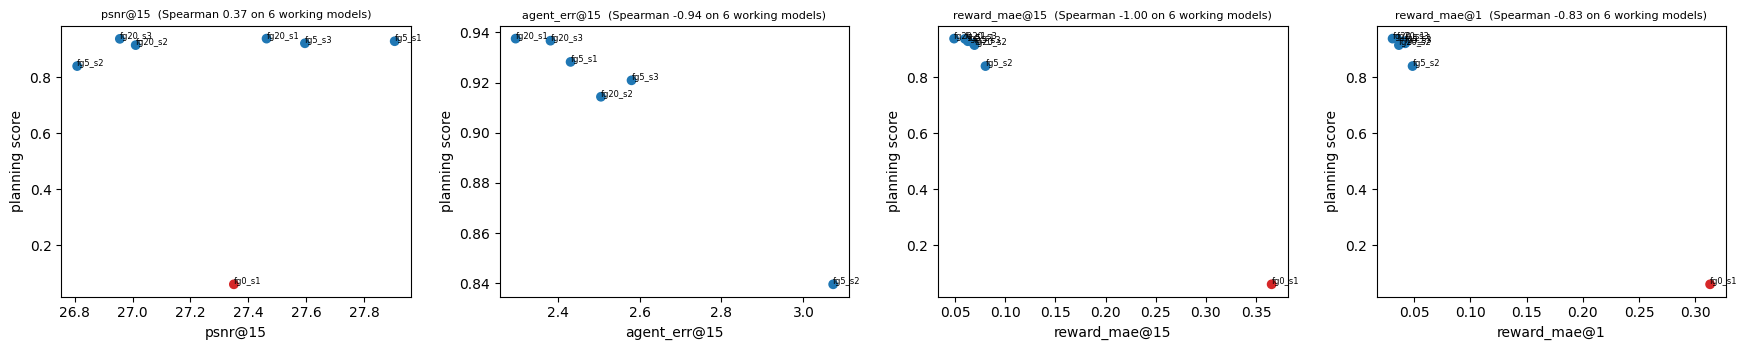

In [11]:
df = planning_table()
joined = df.set_index("run").join(ev.T[["psnr@15", "agent_err@15", "reward_mae@15", "reward_mae@1"]])
metrics = ["psnr@15", "agent_err@15", "reward_mae@15", "reward_mae@1"]
works = joined["score"] > 0.5   # models that actually plan (fg0 does not draw the agent and plans like random)
fig, axes = plt.subplots(1, len(metrics), figsize=(4.4 * len(metrics), 3.6))
for ax, m in zip(axes, metrics):
    x, y = joined[m].astype(float), joined["score"].astype(float)
    ax.scatter(x, y, c=["tab:blue" if w else "tab:red" for w in works])
    for run, xi, yi in zip(joined.index, x, y):
        ax.annotate(run.replace("_1000ep", ""), (xi, yi), fontsize=6)
    ok = works & x.notna()
    try:
        from scipy.stats import spearmanr
        rho = spearmanr(x[ok], y[ok])[0]
        ax.set_title(f"{m}  (Spearman {rho:.2f} on {int(ok.sum())} working models)", fontsize=8)
    except Exception:
        ax.set_title(m, fontsize=8)
    ax.set_xlabel(m); ax.set_ylabel("planning score")
plt.tight_layout(); plt.show()

## 8. Sensibilité aux réglages du CEM
Sur le **meilleur checkpoint**, 30 épisodes par configuration (mêmes épisodes pour toutes). Les réglages par défaut (horizon 6, 1024 échantillons) viennent de cette grille ; comme les mêmes épisodes servent à choisir et à comparer, la section 9 les valide sur des épisodes neufs.

In [12]:
RUN_SENSITIVITY = True
if RUN_SENSITIVITY:
    best = planning_table().sort_values("score").iloc[-1]["run"]
    print("sensitivity on:", best)
    rows = []
    for horizon in (6, 12, 20):
        for samples in (64, 256, 1024):
            out = f"planning_h{horizon}_n{samples}"
            plan(best, out=out, episodes=30, baselines=False, horizon=horizon,
                 samples=samples, elites=max(2, samples // 8))
            res = load_plan(best, out)
            if res:
                rows.append({"horizon": horizon, "samples": samples, "return": res["cem"]["return_mean"],
                             "success": res["cem"]["success_rate"], "ms_per_step": 1000 * res["cem"]["seconds_per_step"]})
    display(pd.DataFrame(rows).round(3))

sensitivity on: fg20_1000ep_s1


,horizon,samples,return,success,ms_per_step
0,6,64,-4.783,0.933,37.906
1,6,256,-4.392,0.933,37.143
2,6,1024,-4.236,0.933,37.915
3,12,64,-5.326,0.933,66.239
4,12,256,-4.809,0.933,66.881
5,12,1024,-4.486,0.933,71.557
6,20,64,-6.075,0.867,104.866
7,20,256,-5.294,0.967,104.763
8,20,1024,-4.852,0.967,115.551


## 9. Validation finale sur des épisodes neufs
Graine d'épisodes 5000, jamais utilisée pour choisir un réglage, avec les réglages par défaut du CEM. Le **score** (normalisé par l'aléatoire et l'oracle sur les mêmes épisodes) se compare directement à celui de la section 5.

In [13]:
SEED = 5000
for name in RUNS_FOUND:
    plan(name, out="planning_fresh")
SEED = 1000
fresh = planning_table("planning_fresh")
display(fresh.round(3))
if len(fresh) and "score" in fresh:
    display(fresh.groupby("variant")[["cem_return", "success", "score"]].agg(["mean", "std"]).round(3))

fg0_1000ep_s1 [planning_fresh] done in 200s
   cem: return   -40.53 ± 18.12 | final dist 0.857 | success 0.01 | 38.9 ms/step
    random: return   -44.66 ± 19.50 | final dist 0.953 | success 0.00 | 0.3 ms/step
    oracle: return    -2.62 ±  2.16 | final dist 0.000 | success 1.00 | 0.2 ms/step
fg20_1000ep_s1 [planning_fresh] done in 203s
   cem: return    -4.23 ±  2.55 | final dist 0.026 | success 0.99 | 39.0 ms/step
    random: return   -44.66 ± 19.50 | final dist 0.953 | success 0.00 | 0.2 ms/step
    oracle: return    -2.62 ±  2.16 | final dist 0.000 | success 1.00 | 0.1 ms/step
fg20_1000ep_s2 [planning_fresh] done in 209s
   cem: return    -4.82 ±  2.94 | final dist 0.040 | success 0.97 | 39.5 ms/step
    random: return   -44.66 ± 19.50 | final dist 0.953 | success 0.00 | 0.3 ms/step
    oracle: return    -2.62 ±  2.16 | final dist 0.000 | success 1.00 | 0.2 ms/step
fg20_1000ep_s3 [planning_fresh] done in 208s
   cem: return    -4.49 ±  2.57 | final dist 0.034 | success 0.98 | 39.7 m

,run,variant,cem_return,cem_sd,final_dist,success,ms_per_step,random,oracle,score
0,fg0_1000ep_s1,fg0,-40.531,18.121,0.857,0.01,38.929,-44.661,-2.62,0.098
1,fg20_1000ep_s1,fg20,-4.233,2.546,0.026,0.99,38.971,-44.661,-2.62,0.962
2,fg20_1000ep_s2,fg20,-4.819,2.937,0.040,0.97,39.513,-44.661,-2.62,0.948
3,fg20_1000ep_s3,fg20,-4.489,2.570,0.034,0.98,39.712,-44.661,-2.62,0.956
4,fg5_1000ep_s1,fg5,-5.216,8.322,0.048,0.99,39.840,-44.661,-2.62,0.938
5,fg5_1000ep_s2,fg5,-7.082,3.874,0.087,0.70,39.945,-44.661,-2.62,0.894
6,fg5_1000ep_s3,fg5,-5.031,3.215,0.045,0.93,39.698,-44.661,-2.62,0.943


cem_return        success         score       
              mean    std    mean    std   mean    std
variant                                               
fg0        -40.531    NaN   0.010    NaN  0.098    NaN
fg20        -4.514  0.294   0.980  0.010  0.955  0.007
fg5         -5.776  1.134   0.873  0.153  0.925  0.027

## 10. GIF du meilleur checkpoint piloté par le planificateur

checkpoint: fg20_1000ep_s1
fg20_1000ep_s1 [planning_gif] done in 6s
   cem: return    -2.26 ±  0.00 | final dist 0.014 | success 1.00 | 49.3 ms/step


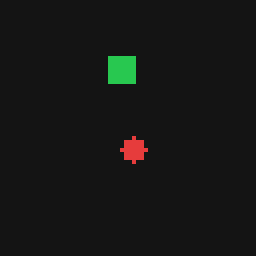

In [14]:
best = df.sort_values("score").iloc[-1]["run"] if "score" in df else RUNS_FOUND[0]
print("checkpoint:", best)
d = plan(best, out="planning_gif", episodes=1, gif=True, baselines=False, force=True)
if d is not None:
    display(Image(filename=str(d / "plan.gif")))